# 06 Models (group F)

All functions are defined in this notebook, as you asked. Logic comes from CODE_PLAN.md section 4 and VALIDATION_PLAN.md (A3 folds, A4 macro F1, A5 logistic regression). Each function has a LOGIC / EDGE CASES / NOT HANDLED / CHECKED BY comment above it, and a test cell right after it.

Imported from `src/` (already written and tested): `make_loro_folds`, `per_class_f1`, `bootstrap_ci`, `MajorityBaseline`, `GBMModel`, `Recording`.

Cells tagged HEAVY take minutes. Everything else is fast.

Scope of this run: offline only. The features CSV was built offline (whole-night scaling, `_next4` context), so a causal run needs a second CSV first.

| Section | What |
|---|---|
| 1 | load the table |
| 2 | `make_xy` |
| 3 | `macro_f1_per_person` |
| 4 | `run_folds` |
| 5 | columns, folds |
| 6 | baseline |
| 7 | `LogRegFeatures`, `tune_settings` (model 1a) |
| 8 | GBM tuning and run (model 1) |
| 9 | `build_interval_sequences` |
| 10 | `IntervalCNN`, `CNNModel` (model 2) |
| 11 | summary |

In [20]:
import os
import sys, time, warnings
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from splits import make_loro_folds, assert_no_person_overlap
from metrics import per_class_f1, bootstrap_ci, paired_difference
from models import MajorityBaseline, GBMModel

CSV = ROOT / "data" / "derived" / "features_all35.csv"
INTERVALS_CSV = ROOT / "data" / "derived" / "intervals_all35.csv"
DATA_ROOT = Path(os.environ.get("DREAMT_ROOT", ROOT / "data" / "raw"))
CLASSES = ("W", "NREM", "REM")
LABELS = [0, 1, 2]
SEED = 20261011
print("project root:", ROOT)

project root: .


## 1. Load

One row per usable 30 s epoch. Number to check: 28,189 rows. The figure shows each person's share of W, NREM and REM.

rows, columns: (28189, 47)
stage3 counts: {'NREM': 18375, 'W': 7141, 'REM': 2673}
people: 35 | share of epochs passing the quality gate: 0.743
people with any N3: 16


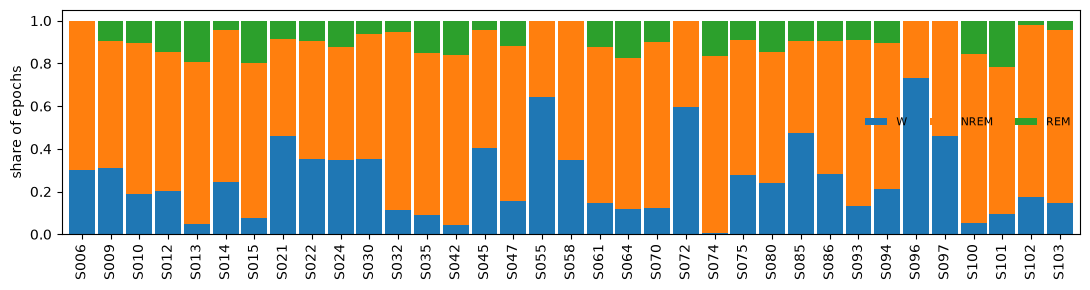

In [21]:
df = pd.read_csv(CSV)
print("rows, columns:", df.shape)
print("stage3 counts:", df["stage3"].value_counts().to_dict())
print("people:", df.subject.nunique(), "| share of epochs passing the quality gate:", round(df["pass"].mean(), 3))
n3_people = sorted(df.loc[df.stage5 == "N3", "subject"].unique())
print("people with any N3:", len(n3_people))

tab = df.groupby(["subject", "stage3"]).size().unstack(fill_value=0)[list(CLASSES)]
tab = tab.div(tab.sum(axis=1), axis=0)
ax = tab.plot.bar(stacked=True, figsize=(11, 3), width=0.9)
ax.set_ylabel("share of epochs"); ax.set_xlabel("")
ax.legend(ncol=3, fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## 2. make_xy

Logic: check the columns exist and none of them is a label, an ID or the gate. Drop rows with no label. A label value outside `CLASSES` raises an error, so nothing disappears silently. Take the feature columns in the order given, keep NaN as NaN, turn labels into integer codes in the fixed class order, and return the original row numbers so predictions can be joined back.

Two choices of mine, for you to change: `t_start` (time into the night) is blocked as a feature because it lets a model learn the shape of a night; the `pass` flag is not returned, read it later with `df.loc[index, "pass"]`.

In [22]:
FORBIDDEN = {"stage3", "stage5", "subject", "epoch", "t_start", "pass"}


# LOGIC: see the markdown above. X is float64 with NaN kept; y holds integer codes in the
#   order of `classes`; subjects and index come from the kept rows.
# EDGE CASES: NaN label dropped; label outside classes raises; leaky column raises
#   (checked before the missing-column check); missing column raises KeyError.
# NOT HANDLED: filtering on the quality gate (decision 3 in CODE_PLAN is still open).
# CHECKED BY: the next cell.
def make_xy(df, cols, label="stage3", classes=CLASSES):
    """Build model inputs from the epoch table.

    df: epoch table (features_all35.csv layout). cols: feature columns, their order is
    the column order of X. label: target column. classes: allowed label values; their
    order gives the integer codes.
    Returns X (n, p) float64 with NaN kept, y (n,) int codes, subjects (n,) IDs,
    index (n,) original row labels of df. Rows with a NaN label are dropped.
    Raises ValueError for a label/ID/gate column in cols or a label value outside
    classes, KeyError for a missing column.
    """
    cols = list(cols)
    bad = [c for c in cols if c in FORBIDDEN]
    if bad:
        raise ValueError(f"label, ID or gate columns cannot be features: {bad}")
    missing = [c for c in cols + [label, "subject"] if c not in df.columns]
    if missing:
        raise KeyError(f"missing columns: {missing}")
    lab = df[label]
    ok = lab.notna()
    unknown = set(lab[ok].unique()) - set(classes)
    if unknown:
        raise ValueError(f"label values outside classes: {sorted(unknown)}")
    sub = df.loc[ok]
    code = {c: i for i, c in enumerate(classes)}
    X = sub[cols].to_numpy("float64")
    y = sub[label].map(code).to_numpy(int)
    return X, y, sub["subject"].to_numpy(object), sub.index.to_numpy()

In [23]:
def _toy():
    return pd.DataFrame({
        "subject": ["S1", "S1", "S2", "S2"], "epoch": [0, 1, 0, 1],
        "t_start": [0., 30., 0., 30.], "pass": [True] * 4,
        "stage5": ["W", "N2", "R", "N3"],
        "hr_mean": [60., np.nan, 70., 72.], "motion": [.1, .2, .3, .4],
        "stage3": ["W", "NREM", "REM", np.nan],
    })

X_, y_, s_, i_ = make_xy(_toy(), ["hr_mean", "motion"])
assert X_.shape == (3, 2) and np.isnan(X_[1, 0]) and list(i_) == [0, 1, 2]   # NaN label dropped, NaN feature kept
assert list(y_) == [0, 1, 2]                                                  # codes follow class order
assert list(make_xy(_toy(), ["motion", "hr_mean"])[0][:, 0]) == [.1, .2, .3]  # column order kept
d = _toy(); assert list(make_xy(d, ["motion"])[2]) == list(d.loc[make_xy(d, ["motion"])[3], "subject"])
for bad in FORBIDDEN:
    try:
        make_xy(_toy(), ["motion", bad]); raise SystemExit(f"no error for {bad}")
    except ValueError:
        pass
d = _toy(); d.loc[0, "stage3"] = "N9"
try:
    make_xy(d, ["motion"]); raise SystemExit("no error for unknown label")
except ValueError:
    pass
try:
    make_xy(_toy(), ["nope"]); raise SystemExit("no error for missing column")
except KeyError:
    pass
print("make_xy: all checks passed")

make_xy: all checks passed


## 3. macro_f1_per_person

Logic: for one person, compute the F1 of each stage from the confusion matrix (the existing `per_class_f1`). A stage in the reference or in the predictions has a value. A stage the model predicted but the person never had gets 0. A stage in neither is NaN and is left out of the mean. The mean over stages is that person's macro F1; the number of stages averaged is returned beside it.

In [24]:
# LOGIC: see the markdown above (VALIDATION_PLAN A4, decided 2026-10-17).
# EDGE CASES: stage in neither y nor yhat is left out; predicted but absent scores 0;
#   a person whose stages are all NaN gets NaN.
# NOT HANDLED: weighting stages; every stage counts equally by design.
# CHECKED BY: the next cell.
def macro_f1_per_person(preds, labels, person_col="subject", y_col="y", yhat_col="yhat"):
    """preds: table with one row per epoch (person, true code, predicted code).
    Returns a table indexed by person with macro_f1 and n_stages (stages averaged)."""
    rows = []
    for s, g in preds.groupby(person_col, sort=True):
        f1 = per_class_f1(g[y_col], g[yhat_col], list(labels))
        rows.append({"subject": s, "macro_f1": float(f1.mean()), "n_stages": int(f1.notna().sum())})
    return pd.DataFrame(rows).set_index("subject")

In [25]:
p = pd.DataFrame({"subject": "A", "y": [0, 1, 2, 2], "yhat": [0, 1, 2, 2]})
assert macro_f1_per_person(p, LABELS).loc["A", "macro_f1"] == 1.0                      # perfect gives 1
p = pd.DataFrame({"subject": "A", "y": [0, 0, 1, 1], "yhat": [0, 1, 1, 1]})
r = macro_f1_per_person(p, LABELS).loc["A"]
assert abs(r.macro_f1 - (2 / 3 + 4 / 5) / 2) < 1e-12 and r.n_stages == 2               # hand-computed, stage 2 left out
p = pd.DataFrame({"subject": "A", "y": [0, 0], "yhat": [0, 2]})
r = macro_f1_per_person(p, LABELS).loc["A"]
assert abs(r.macro_f1 - (2 / 3 + 0) / 2) < 1e-12 and r.n_stages == 2                   # predicted but absent scores 0
print("macro_f1_per_person: all checks passed")
print(p)

macro_f1_per_person: all checks passed
  subject  y  yhat
0       A  0     0
1       A  0     2


## 4. run_folds

Logic: the one loop every model goes through. Check no person sits in two of train, tune and test. For each fold, pick the rows of the three groups, refuse to continue if a class is missing from the training people, make a fresh model, fit it on the training rows (models that set `uses_tune = True` also get the tuning rows for early stopping), predict the test person, and keep one row per test epoch. Returns one long table: person, original row, true code, predicted code, fold, model name.

Class probabilities from the plan are left out for now; they can be added when a figure needs them.

In [26]:
# LOGIC: see the markdown above.
# EDGE CASES: class missing from train raises; model_factory is called once per fold so
#   no state leaks between folds.
# NOT HANDLED: class probabilities; parallel folds.
# CHECKED BY: the next cell.
def run_folds(model_factory, X, y, subjects, index, folds, name, classes=CLASSES, verbose=True):
    """Fit and predict fold by fold. model_factory(): returns a fresh model with fit/predict.
    Returns a table with columns subject, row, y, yhat, fold, model."""
    assert_no_person_overlap(folds)
    out, t0 = [], time.time()
    for i, f in enumerate(folds):
        tr = np.isin(subjects, f["train"]); tu = np.isin(subjects, f["tune"]); te = np.isin(subjects, f["test"])
        if len(np.unique(y[tr])) < len(classes):
            raise ValueError(f"fold {i}: a class is missing from the training people")
        model = model_factory()
        if getattr(model, "uses_tune", False):
            model.fit(X[tr], y[tr], tune=(X[tu], y[tu]))
        else:
            model.fit(X[tr], y[tr])
        yhat = np.asarray(model.predict(X[te])).astype(int)
        out.append(pd.DataFrame({"subject": subjects[te], "row": index[te], "y": y[te],
                                 "yhat": yhat, "fold": i, "model": name}))
        if verbose:
            print(f"{name} fold {i + 1}/{len(folds)} done, {time.time() - t0:.0f}s elapsed", end="\r")
    if verbose:
        print()
    return pd.concat(out, ignore_index=True)

In [27]:
subj_t = np.repeat(np.array(["a", "b", "c", "d", "e", "f"], dtype=object), 4)
y_t = np.tile([0, 0, 1, 2], 6); X_t = np.zeros((24, 2)); idx_t = np.arange(24) + 100
folds_t = [{"test": ["a"], "tune": ["b"], "train": ["c", "d", "e", "f"]},
           {"test": ["b"], "tune": ["c"], "train": ["a", "d", "e", "f"]}]
r = run_folds(lambda: MajorityBaseline(), X_t, y_t, subj_t, idx_t, folds_t, "m", verbose=False)
assert sorted(r.subject.unique()) == ["a", "b"] and len(r) == 8                        # only test people, once each
assert set(r.row) == set(idx_t[np.isin(subj_t, ["a", "b"])])                           # rows map back
assert (r.yhat == 0).all()                                                             # majority class is 0
try:
    bad = [{"test": ["a"], "tune": ["b"], "train": ["a", "c"]}]
    run_folds(lambda: MajorityBaseline(), X_t, y_t, subj_t, idx_t, bad, "m", verbose=False); raise SystemExit("overlap not caught")
except AssertionError:
    pass
y_m = y_t.copy(); y_m[np.isin(subj_t, ["c", "d", "e", "f"])] = 0                       # classes 1,2 only in a, b
try:
    run_folds(lambda: MajorityBaseline(), X_t, y_m, subj_t, idx_t, folds_t[:1], "m", verbose=False); raise SystemExit("missing class not caught")
except ValueError:
    pass
print("run_folds: all checks passed")

run_folds: all checks passed


## 5. Columns and folds

Model inputs: the 10 per-person scaled features, plus the mean of the previous 4 epochs and of the next 4 epochs of each (30 columns). Number: the share of NaN cells. Figure: NaN share per column. Folds are leave-one-recording-out (35 folds), each with 4 tuning people, 2 of them with N3.

10 scaled features + 10 past + 10 next = 30 columns
X (28189, 30) | y counts [7141, 18375, 2673] | NaN share of cells: 0.123


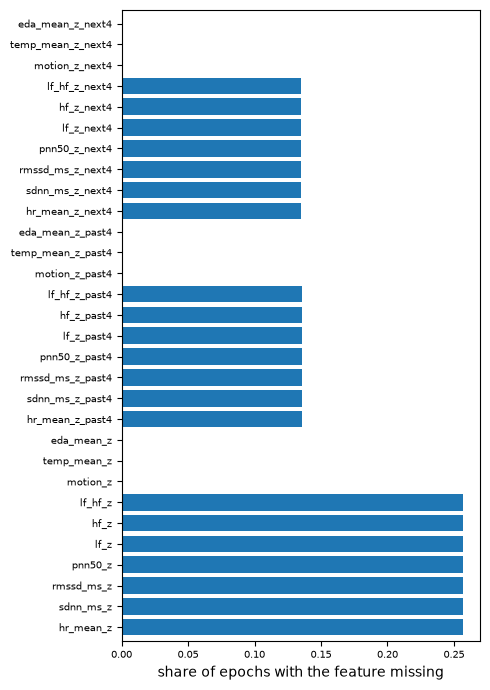

folds: 35 | fold 0 sizes (train, tune, test): 30 4 1


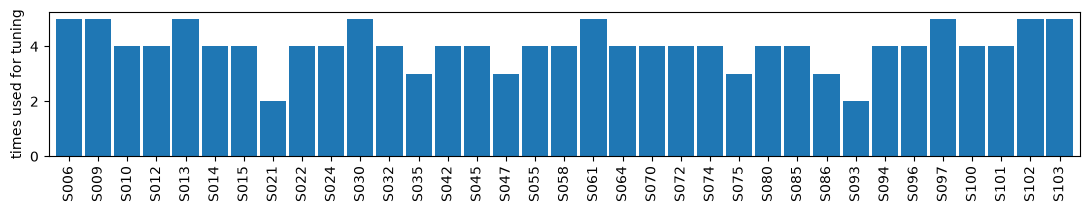

In [28]:
Z = [c for c in df.columns if c.endswith("_z")]
PAST = [c + "_past4" for c in Z]; NEXT = [c + "_next4" for c in Z]
assert all(c in df.columns for c in PAST + NEXT), "context columns missing"
COLS = Z + PAST + NEXT
print(len(Z), "scaled features +", len(PAST), "past +", len(NEXT), "next =", len(COLS), "columns")

X, y, subjects, index = make_xy(df, COLS)
print("X", X.shape, "| y counts", np.bincount(y).tolist(), "| NaN share of cells:", round(float(np.isnan(X).mean()), 3))
ax = pd.Series(np.isnan(X).mean(0), index=COLS).plot.barh(figsize=(5, 7), width=0.8)
ax.set_xlabel("share of epochs with the feature missing"); ax.tick_params(labelsize=7)
plt.tight_layout(); plt.show()

people = sorted(df.subject.unique())
folds = make_loro_folds(people, n3_people)
print("folds:", len(folds), "| fold 0 sizes (train, tune, test):",
      len(folds[0]["train"]), len(folds[0]["tune"]), len(folds[0]["test"]))
duty = pd.Series(Counter(s for f in folds for s in f["tune"])).reindex(people).fillna(0)
ax = duty.plot.bar(figsize=(11, 2.2), width=0.9); ax.set_ylabel("times used for tuning")
plt.tight_layout(); plt.show()

## 6. Baseline (model 0)

Always predicts the most common stage in the training people. Number: the median per-person macro F1 with a 95% interval from resampling people 10,000 times. Figure: one dot per person.

baseline fold 35/35 done, 0s elapsed
baseline: median per-person macro F1 0.278  95% CI [0.262, 0.288]  people 35  mean stages averaged 2.83


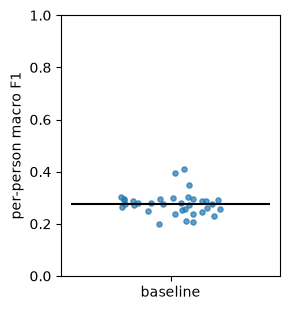

In [29]:
def score(preds, name):
    t = macro_f1_per_person(preds, LABELS)
    med, lo, hi = bootstrap_ci(t["macro_f1"])
    print(f"{name}: median per-person macro F1 {med:.3f}  95% CI [{lo:.3f}, {hi:.3f}]"
          f"  people {len(t)}  mean stages averaged {t.n_stages.mean():.2f}")
    return t


def dot_plot(tables):
    fig, ax = plt.subplots(figsize=(1.6 + 1.4 * len(tables), 3.2))
    for i, (name, t) in enumerate(tables.items()):
        v = t["macro_f1"].dropna().to_numpy()
        jit = np.random.default_rng(0).uniform(-0.15, 0.15, v.size)
        ax.scatter(np.full(v.size, i) + jit, v, s=14, alpha=0.7)
        ax.hlines(np.median(v), i - 0.3, i + 0.3, color="k")
    ax.set_xticks(range(len(tables))); ax.set_xticklabels(list(tables))
    ax.set_ylabel("per-person macro F1"); ax.set_ylim(0, 1)
    plt.tight_layout(); plt.show()


preds_base = run_folds(lambda: MajorityBaseline(), X, y, subjects, index, folds, "baseline")
tab_base = score(preds_base, "baseline")
dot_plot({"baseline": tab_base})

## 7. Logistic regression (model 1a) and tuning

`LogRegFeatures` logic: logistic regression cannot take NaN. Inside the model only, fill each NaN with the training median of that column and add a 0/1 missing flag per column. Standardise with training statistics. Fit an L2 logistic regression with balanced class weights (the same weighting the GBM uses). The stored features stay NaN.

`tune_settings` logic: for each candidate setting, fit on the training people of each fold, score on that fold's tuning people (mean of per-person macro F1), average over folds, and sort. Test people are never touched.

In [30]:
# LOGIC: see the markdown above (VALIDATION_PLAN A5, model 1a).
# EDGE CASES: all-NaN column in training gets median 0; zero-variance column keeps sd 1.
# NOT HANDLED: class weights are "balanced" (decision 4 in CODE_PLAN is still open).
# CHECKED BY: the test cell below.
class LogRegFeatures:
    def __init__(self, C=1.0):
        self.C = C

    def _prep(self, X):
        X = np.asarray(X, "float64")
        Xf = np.where(np.isnan(X), self.med_, X)
        return np.hstack([(Xf - self.mu_) / self.sd_, np.isnan(X).astype("float64")])

    def fit(self, X, y):
        from sklearn.linear_model import LogisticRegression
        X = np.asarray(X, "float64")
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            med = np.nanmedian(X, axis=0)
        self.med_ = np.where(np.isnan(med), 0.0, med)
        Xf = np.where(np.isnan(X), self.med_, X)
        self.mu_ = Xf.mean(0); sd = Xf.std(0); self.sd_ = np.where(sd == 0, 1.0, sd)
        self.model_ = LogisticRegression(C=self.C, class_weight="balanced", max_iter=500).fit(self._prep(X), y)
        return self

    def predict(self, X):
        return self.model_.predict(self._prep(X))

In [31]:
rng = np.random.default_rng(1)
yy = rng.integers(0, 3, 600); XX = rng.normal(size=(600, 4)) + 2.0 * yy[:, None]
XX[rng.random(XX.shape) < 0.1] = np.nan
m = LogRegFeatures(C=1.0).fit(XX, yy)
assert (m.predict(XX) == yy).mean() > 0.8                                              # learns a separable set with NaN in it
Xn = XX[:5].copy(); Xn[0, 0] = np.nan
P = m._prep(Xn)
assert np.isclose(P[0, 0], (m.med_[0] - m.mu_[0]) / m.sd_[0]) and P[0, 4] == 1.0       # NaN -> median, flag set
assert P[1, 4] == (1.0 if np.isnan(XX[1, 0]) else 0.0)
m2 = LogRegFeatures().fit(np.full((30, 2), np.nan), np.arange(30) % 3)                 # all-NaN column does not crash
print("LogRegFeatures: all checks passed")

LogRegFeatures: all checks passed


In [32]:
# LOGIC: see the markdown above.
# EDGE CASES: settings are dicts passed to model_factory(**setting); a fold's tuning
#   people with a missing stage are handled by macro_f1_per_person.
# NOT HANDLED: parallel fits (each fit is single process).
# CHECKED BY: the next cell.
def tune_settings(model_factory, settings, X, y, subjects, folds, labels=LABELS):
    """Returns a table: the setting values, tune_macro_f1, and setting (its index in the list),
    best first."""
    rows = []
    for k, s in enumerate(settings):
        scores = []
        for f in folds:
            tr = np.isin(subjects, f["train"]); tu = np.isin(subjects, f["tune"])
            m = model_factory(**s).fit(X[tr], y[tr])
            p = pd.DataFrame({"subject": subjects[tu], "y": y[tu],
                              "yhat": np.asarray(m.predict(X[tu])).astype(int)})
            scores.append(macro_f1_per_person(p, labels)["macro_f1"].mean())
        rows.append({**s, "tune_macro_f1": float(np.nanmean(scores)), "setting": k})
        print(f"setting {k + 1}/{len(settings)}: tune macro F1 {rows[-1]['tune_macro_f1']:.3f}", end="\r")
    print()
    return pd.DataFrame(rows).sort_values("tune_macro_f1", ascending=False).reset_index(drop=True)


# LOGIC: at most n random GBM settings with a fixed seed (VALIDATION_PLAN section 6).
#   early_stopping is off: the number of trees (max_iter) is chosen on tuning people.
# CHECKED BY: the next cell.
def gbm_settings(n=20, seed=SEED):
    rng = np.random.default_rng(seed)
    return [{"learning_rate": float(np.exp(rng.uniform(np.log(0.03), np.log(0.3)))),
             "max_leaf_nodes": int(rng.choice([8, 16, 31, 63])),
             "max_iter": int(rng.choice([100, 200, 300])),
             "min_samples_leaf": int(rng.choice([20, 50, 100, 200])),
             "l2_regularization": float(np.exp(rng.uniform(np.log(1e-3), np.log(10)))),
             "early_stopping": False} for _ in range(n)]

In [33]:
rng = np.random.default_rng(2)
subj_s = np.repeat(np.array([f"p{i}" for i in range(8)], dtype=object), 60)
y_s = rng.integers(0, 3, subj_s.size); X_s = rng.normal(size=(subj_s.size, 3)) + 2.0 * y_s[:, None]
folds_s = [{"test": ["p0"], "tune": ["p1", "p2"], "train": [f"p{i}" for i in range(3, 8)]},
           {"test": ["p3"], "tune": ["p4", "p5"], "train": ["p0", "p1", "p2", "p6", "p7"]}]
res = tune_settings(lambda **s: LogRegFeatures(**s), [{"C": 1e-9}, {"C": 1.0}], X_s, y_s, subj_s, folds_s)
assert res.iloc[0]["C"] == 1.0 and res.iloc[0]["tune_macro_f1"] > res.iloc[1]["tune_macro_f1"]   # sensible setting wins
g = gbm_settings()
assert len(g) == 20 and g == gbm_settings() and all(isinstance(s["max_leaf_nodes"], int) for s in g)  # seeded, plain ints
print("tune_settings, gbm_settings: all checks passed")

setting 2/2: tune macro F1 0.972
tune_settings, gbm_settings: all checks passed


### Run model 1a. HEAVY (about a minute)

Tuning uses the tuning people of the first 3 folds only, once, then the chosen penalty is used in all 35 folds. This is decision 2 in CODE_PLAN (tune per fold, or once); change `TUNE_FOLDS` to `folds` to use all folds.

setting 8/8: tune macro F1 0.415
          C  tune_macro_f1
0   19.3070         0.4148
1  100.0000         0.4147
2    3.7276         0.4143
3    0.7197         0.4141
4    0.1389         0.4137
5    0.0268         0.4108
6    0.0052         0.4057
7    0.0010         0.3972
chosen C: 19.306977288832496
logreg fold 35/35 done, 9s elapsed
logreg: median per-person macro F1 0.403  95% CI [0.362, 0.438]  people 35  mean stages averaged 3.00


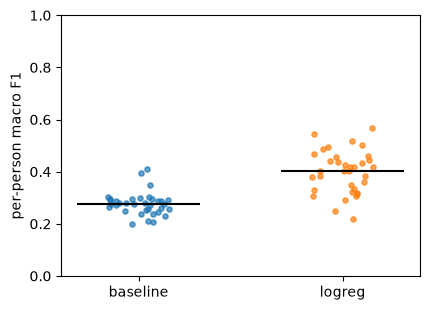

In [34]:
TUNE_FOLDS = folds[:3]
lr_settings = [{"C": float(c)} for c in np.logspace(-3, 2, 8)]
lr_tune = tune_settings(lambda **s: LogRegFeatures(**s), lr_settings, X, y, subjects, TUNE_FOLDS)
print(lr_tune[["C", "tune_macro_f1"]].round(4).to_string())
best_C = lr_settings[int(lr_tune.iloc[0]["setting"])]["C"]
print("chosen C:", best_C)
preds_lr = run_folds(lambda: LogRegFeatures(C=best_C), X, y, subjects, index, folds, "logreg")
tab_lr = score(preds_lr, "logreg")
dot_plot({"baseline": tab_base, "logreg": tab_lr})

## 8. Gradient boosting (model 1). HEAVY (several minutes)

Same procedure: 20 random settings tuned once on the tuning people of the first 3 folds, then all 35 folds with the chosen setting.

In [35]:
settings_gbm = gbm_settings(20)
gbm_tune = tune_settings(lambda **s: GBMModel(**s), settings_gbm, X, y, subjects, TUNE_FOLDS)
print(gbm_tune[["learning_rate", "max_leaf_nodes", "max_iter", "min_samples_leaf", "tune_macro_f1"]].head(5).round(4).to_string())
best_gbm = settings_gbm[int(gbm_tune.iloc[0]["setting"])]
print("chosen:", best_gbm)
preds_gbm = run_folds(lambda: GBMModel(**best_gbm), X, y, subjects, index, folds, "gbm")
tab_gbm = score(preds_gbm, "gbm")
dot_plot({"baseline": tab_base, "logreg": tab_lr, "gbm": tab_gbm})

KeyboardInterrupt: 

## 9. build_interval_sequences (CNN input)

Logic: the features CSV has no beat intervals, so they are rebuilt once per person with `Recording` and cached in `data/derived/intervals_all35.csv`. For each person, put the kept intervals on a regular 4 Hz grid: linear interpolation between neighbouring kept beats, but a grid point whose neighbouring kept beats are more than `max_gap` (2 s) apart is MISSING, not filled. Missing points get value 0 and a flag of 1 in a second channel. Values are centred and scaled with that person's median and spread of kept intervals.

Each epoch's input is its own 30 s plus the previous `k` epochs, and, offline only, the next `k` epochs. Windows that run off either end of the night are padded as missing.

Known limit: the centring and scaling use the whole night, so a truly causal run needs a running version.

In [ ]:
# LOGIC: see the markdown above. One grid per person, built once; each epoch slices it.
# EDGE CASES: a grid point exactly on a beat uses that beat; the first beat has no left
#   neighbour so it is missing; zero spread keeps scale 1. Causal mode also marks as
#   missing any grid point whose interpolation needs a beat at or after the epoch end,
#   because that beat is in the future (the epoch is [start, start + 30)).
# NOT HANDLED: running (causal) normalisation of the values.
# CHECKED BY: the test cell below.
def _grid_one(inter, grid_hz, max_gap, normalise):
    keep = inter["keep"].to_numpy(bool)
    tk = inter["t"].to_numpy("float64")[keep]; ik = inter["ibi"].to_numpy("float64")[keep]
    t0 = np.floor(tk[0])
    n = int(np.floor((tk[-1] - t0) * grid_hz)) + 1
    g = t0 + np.arange(n) / grid_hz
    j = np.searchsorted(tk, g)
    jl = np.clip(j - 1, 0, tk.size - 1); jr = np.clip(j, 0, tk.size - 1)
    ok = (j > 0) & (j < tk.size) & ((tk[jr] - tk[jl]) <= max_gap)
    val = np.interp(g, tk, ik)
    if normalise:
        sd = ik.std()
        val = (val - np.median(ik)) / (sd if sd > 0 else 1.0)
    return t0, np.where(ok, val, 0.0).astype("float32"), (~ok).astype("float32"), tk[jr]


def build_interval_sequences(intervals_by_subject, subjects, t_starts, k=4, grid_hz=4,
                             causal=False, epoch_s=30, max_gap=2.0, normalise=True):
    """intervals_by_subject: {person: table with t, ibi, keep}. subjects, t_starts: one entry per
    epoch (person, epoch start on the same clock as t). Returns float32 array (n, 2, L):
    channel 0 the interval series, channel 1 the missing flag. L = (k + 1 + (0 if causal else k))
    * epoch_s * grid_hz."""
    subjects = np.asarray(subjects, object); t_starts = np.asarray(t_starts, "float64")
    pre = k * epoch_s * grid_hz; cur = epoch_s * grid_hz
    L = pre + cur + (0 if causal else pre)
    X = np.zeros((len(t_starts), 2, L), "float32"); X[:, 1, :] = 1.0
    for s in np.unique(subjects):
        t0, val, miss, tr = _grid_one(intervals_by_subject[s], grid_hz, max_gap, normalise)
        rows = np.where(subjects == s)[0]
        start = np.round((t_starts[rows] - t0) * grid_hz).astype(int) - pre
        for r, a in zip(rows, start):
            lo, hi = max(a, 0), min(a + L, val.size)
            if hi > lo:
                v = X[r, 0, lo - a:hi - a]; m = X[r, 1, lo - a:hi - a]
                v[:] = val[lo:hi]; m[:] = miss[lo:hi]
                if causal:
                    late = tr[lo:hi] >= t_starts[r] + epoch_s      # interpolated using a beat after the epoch end
                    v[late] = 0.0; m[late] = 1.0
    return X

In [ ]:
tb = np.arange(100.0, 300.0, 1.0)                                    # one beat per second, 200 s
iv = pd.DataFrame({"t": tb, "ibi": 1.0 + 0.001 * (tb - 100.0), "keep": True})
iv.loc[(iv.t >= 190) & (iv.t < 196), "keep"] = False                 # a 7 s hole inside the window (beats 190..195 rejected)
S = build_interval_sequences({"A": iv}, ["A"], [200.0], k=1, causal=False, normalise=False)
assert S.shape == (1, 2, (1 + 1 + 1) * 30 * 4)                       # k=1 offline: 90 s at 4 Hz
t_axis = 200.0 - 30 + np.arange(S.shape[2]) / 4                      # window starts one epoch before t_start
i_ok = np.argmin(abs(t_axis - 180.0))
assert abs(S[0, 0, i_ok] - (1.0 + 0.001 * 80.0)) < 1e-4 and S[0, 1, i_ok] == 0   # known interpolated value
i_hole = np.argmin(abs(t_axis - 192.0)); assert S[0, 1, i_hole] == 1 and S[0, 0, i_hole] == 0   # hole stays missing
C1 = build_interval_sequences({"A": iv}, ["A"], [200.0], k=1, causal=True, normalise=False)
assert C1.shape[2] == 2 * 30 * 4
iv2 = iv.copy(); iv2.loc[iv2.t >= 230, "ibi"] = 5.0                  # change only data after the epoch ends (200 + 30)
C2 = build_interval_sequences({"A": iv2}, ["A"], [200.0], k=1, causal=True, normalise=False)
assert np.array_equal(C1, C2)                                        # causal window never sees later data
P = build_interval_sequences({"A": iv}, ["A"], [100.0], k=1, causal=True, normalise=False)
assert P[0, 1, :30 * 4].min() == 1                                   # the 30 s before the first beat: missing
print("build_interval_sequences: all checks passed")

build_interval_sequences: all checks passed


### Build the sequences. HEAVY (first run: detects beats for all 35 nights, then caches)

Number: how many epochs have a different beat count than the CSV's `n_ibi`. It must be 0, otherwise the two tables sit on different clocks. Figure: one example input window, the interval series with the missing points marked.

epochs whose beat count differs from the CSV: 0
sequence array (28189, 2, 1080) | share of grid points missing: 0.086


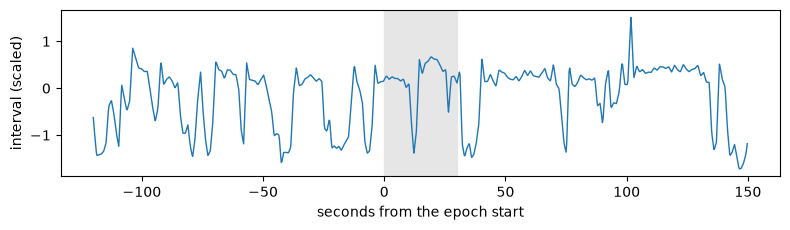

In [ ]:
def load_intervals(subjects, data_root=DATA_ROOT, cache=INTERVALS_CSV):
    if cache.exists():
        allv = pd.read_csv(cache)
    else:
        from recording import Recording
        parts = []
        for s in subjects:
            t0 = time.time()
            iv = Recording.load(s, data_root).intervals.copy()
            iv.insert(0, "subject", s); parts.append(iv)
            print(s, len(iv), "intervals,", round(time.time() - t0), "s")
        allv = pd.concat(parts, ignore_index=True)
        allv.to_csv(cache, index=False)
    return {s: g.drop(columns="subject").reset_index(drop=True) for s, g in allv.groupby("subject")}


intervals = load_intervals(people)

bad = 0
for s, g in df.groupby("subject"):
    iv = intervals[s]; tk = iv["t"].to_numpy()[iv["keep"].to_numpy(bool)]
    ts = g["t_start"].to_numpy()
    n = np.searchsorted(tk, ts + 30, "left") - np.searchsorted(tk, ts, "left")
    bad += int((n != g["n_ibi"].to_numpy()).sum())
print("epochs whose beat count differs from the CSV:", bad)
assert bad == 0, "interval table and features CSV are on different clocks"

t_starts = df.loc[index, "t_start"].to_numpy()
Xseq = build_interval_sequences(intervals, subjects, t_starts, k=4, causal=False)
print("sequence array", Xseq.shape, "| share of grid points missing:", round(float(Xseq[:, 1, :].mean()), 3))

r = int(np.flatnonzero(df.loc[index, "pass"].to_numpy())[1000])
fig, ax = plt.subplots(figsize=(8, 2.4))
tt = (np.arange(Xseq.shape[2]) / 4) - 4 * 30
ax.plot(tt, np.where(Xseq[r, 1] == 1, np.nan, Xseq[r, 0]), lw=1)
ax.axvspan(0, 30, color="0.9"); ax.set_xlabel("seconds from the epoch start"); ax.set_ylabel("interval (scaled)")
plt.tight_layout(); plt.show()

## 10. IntervalCNN and CNNModel (model 2)

`IntervalCNN` logic: three blocks of 1D convolution (kernel 7), batch norm, ReLU and max-pool by 4, then the mean over time, dropout, and a linear layer to the 3 stages. Causal mode pads on the left only, so an output never depends on samples to its right. No architecture search.

`CNNModel` logic: weights the loss by inverse class frequency, trains with AdamW and mini-batches, checks the weighted loss on the tuning people after every epoch, keeps the weights with the lowest tuning loss, and stops after `patience` epochs without improvement. Fixed seed. Runs on the Mac GPU if present. `uses_tune = True` makes `run_folds` pass the tuning people to `fit`.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# LOGIC: see the markdown above.
# EDGE CASES: max-pool uses ceil_mode so the most recent samples are never dropped.
# NOT HANDLED: architecture search (the plan allows none).
# CHECKED BY: the test cell below.
class IntervalCNN(nn.Module):
    def __init__(self, n_classes=3, in_ch=2, causal=False, width=16, dropout=0.3):
        super().__init__()
        self.causal = causal
        ch = [in_ch, width, 2 * width, 4 * width]
        self.convs = nn.ModuleList([nn.Conv1d(ch[i], ch[i + 1], kernel_size=7) for i in range(3)])
        self.bns = nn.ModuleList([nn.BatchNorm1d(ch[i + 1]) for i in range(3)])
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(ch[-1], n_classes)

    def block(self, i, x):
        pad = (6, 0) if self.causal else (3, 3)
        return F.max_pool1d(F.relu(self.bns[i](self.convs[i](F.pad(x, pad)))), 4, ceil_mode=True)

    def forward(self, x):
        for i in range(3):
            x = self.block(i, x)
        return self.head(self.drop(x.mean(dim=2)))


# LOGIC: see the markdown above.
# EDGE CASES: every class must be in y (run_folds checks); best weights restored at the end.
# NOT HANDLED: mixed precision; a causal (running) normalisation of the input values.
# CHECKED BY: the test cell below.
class CNNModel:
    uses_tune = True

    def __init__(self, causal=False, n_classes=3, epochs=30, batch=256, lr=1e-3, patience=5,
                 seed=SEED, device="auto"):
        self.causal, self.n_classes, self.epochs, self.batch = causal, n_classes, epochs, batch
        self.lr, self.patience, self.seed = lr, patience, seed
        self.device = ("mps" if torch.backends.mps.is_available() else "cpu") if device == "auto" else device

    def _loss(self, model, X, y, loss_fn):
        model.eval(); tot, n = 0.0, 0
        with torch.no_grad():
            for b in range(0, len(X), 1024):
                xb = torch.from_numpy(X[b:b + 1024]).to(self.device)
                yb = torch.from_numpy(y[b:b + 1024]).long().to(self.device)
                tot += float(loss_fn(model(xb), yb)) * len(xb); n += len(xb)
        return tot / n

    def fit(self, X, y, tune):
        torch.manual_seed(self.seed); rng = np.random.default_rng(self.seed)
        Xt, yt = tune
        counts = np.bincount(y, minlength=self.n_classes).astype("float64")
        w = torch.tensor(counts.sum() / (self.n_classes * counts), dtype=torch.float32, device=self.device)
        loss_fn = nn.CrossEntropyLoss(weight=w)
        model = IntervalCNN(self.n_classes, X.shape[1], self.causal).to(self.device)
        opt = torch.optim.AdamW(model.parameters(), lr=self.lr, weight_decay=1e-2)
        best, bad, state = np.inf, 0, None
        for ep in range(self.epochs):
            model.train(); perm = rng.permutation(len(X))
            for b in range(0, len(X), self.batch):
                idx = perm[b:b + self.batch]
                xb = torch.from_numpy(X[idx]).to(self.device); yb = torch.from_numpy(y[idx]).long().to(self.device)
                opt.zero_grad(); loss_fn(model(xb), yb).backward(); opt.step()
            tl = self._loss(model, Xt, yt, loss_fn)
            if tl < best - 1e-4:
                best, bad, state = tl, 0, {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= self.patience:
                    break
        model.load_state_dict(state)
        self.model_, self.epochs_run_, self.best_tune_loss_ = model.eval(), ep + 1, best
        return self

    def predict(self, X):
        out = []
        with torch.no_grad():
            for b in range(0, len(X), 1024):
                out.append(self.model_(torch.from_numpy(X[b:b + 1024]).to(self.device)).argmax(1).cpu().numpy())
        return np.concatenate(out)

In [ ]:
torch.manual_seed(0)
net = IntervalCNN(causal=True).eval()
x = torch.randn(2, 2, 120)
x2 = x.clone(); x2[:, :, 80:] = torch.randn(2, 2, 40)               # change only the "future" after sample 80
with torch.no_grad():
    a, b = net.block(0, x), net.block(0, x2)
assert torch.equal(a[:, :, :80 // 4], b[:, :, :80 // 4])            # causal block: earlier outputs unchanged
assert not torch.equal(a, b)                                        # and later outputs do change
rng = np.random.default_rng(3)
yy = rng.integers(0, 3, 240); Xs_ = rng.normal(size=(240, 2, 64)).astype("float32"); Xs_[:, 0, :] += yy[:, None] * 1.5
yt_ = rng.integers(0, 3, 90); Xt_ = rng.normal(size=(90, 2, 64)).astype("float32"); Xt_[:, 0, :] += yt_[:, None] * 1.5
m = CNNModel(epochs=40, patience=8, device="cpu").fit(Xs_, yy, tune=(Xt_, yt_))
assert (m.predict(Xs_) == yy).mean() > 0.9                          # learns a separable synthetic set
print("IntervalCNN, CNNModel: all checks passed (epochs run:", m.epochs_run_, ")")

IntervalCNN, CNNModel: all checks passed (epochs run: 40 )


### Run model 2. HEAVY (timing run on the first 3 folds)

Number: median per-person macro F1 on the 3 test people. Each fold trains on about 30 people, so time one fold before running all 35. To run all of them set `CNN_FOLDS = folds`. Compare with the other models only on the same people.

cnn fold 3/3 done, 32s elapsed
cnn: median per-person macro F1 0.433  95% CI [0.362, 0.476]  people 3  mean stages averaged 3.00
same people, other models:
  baseline: median 0.276
  logreg: median 0.496
  gbm: median 0.433


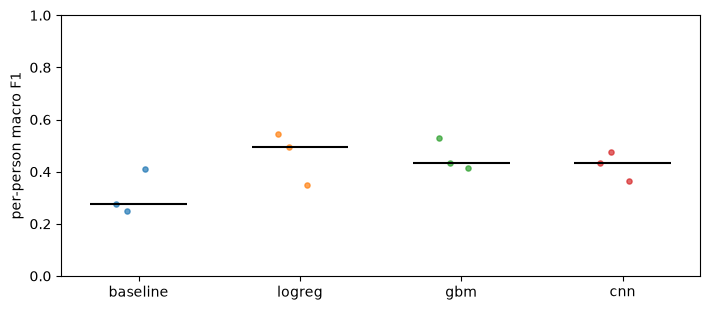

In [ ]:
CNN_FOLDS = folds[:3]
preds_cnn = run_folds(lambda: CNNModel(causal=False), Xseq, y, subjects, index, CNN_FOLDS, "cnn")
tab_cnn = score(preds_cnn, "cnn")
common = tab_cnn.index
print("same people, other models:")
for nm, t in [("baseline", tab_base), ("logreg", tab_lr), ("gbm", tab_gbm)]:
    print(f"  {nm}: median {t.loc[common, 'macro_f1'].median():.3f}")
dot_plot({"baseline": tab_base.loc[common], "logreg": tab_lr.loc[common],
          "gbm": tab_gbm.loc[common], "cnn": tab_cnn})

## 11. Summary

Run this after the HEAVY cells. The CNN row only has the people in `CNN_FOLDS` unless you ran all 35 folds.

baseline    0.278
logreg      0.403
gbm         0.409


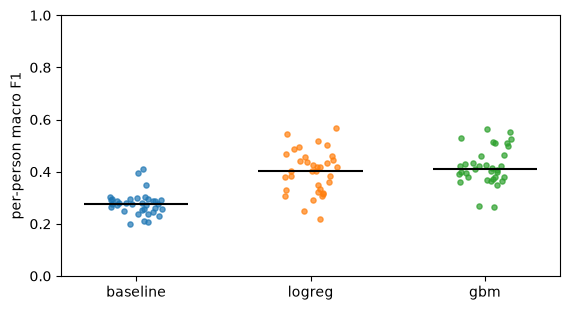

In [ ]:
tabs = {"baseline": tab_base, "logreg": tab_lr, "gbm": tab_gbm}
if "tab_cnn" in globals() and len(tab_cnn) == len(people):
    tabs["cnn"] = tab_cnn
summary = pd.DataFrame({nm: t["macro_f1"] for nm, t in tabs.items()})
print(summary.median().round(3).to_string())
dot_plot(tabs)

logreg pooled per-class F1: {'W': 0.499, 'NREM': 0.553, 'REM': 0.201}


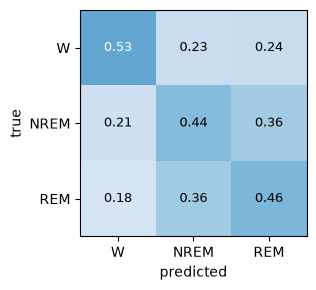

gbm pooled per-class F1: {'W': 0.525, 'NREM': 0.691, 'REM': 0.12}


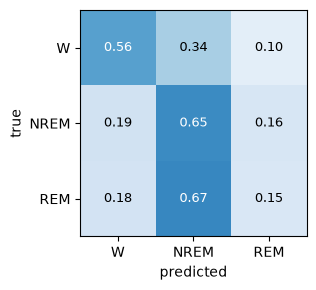

cnn pooled per-class F1: {'W': 0.495, 'NREM': 0.808, 'REM': 0.03}


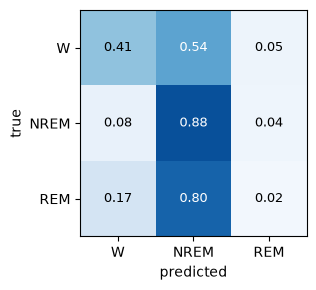

In [ ]:
from metrics import confusion, per_class_f1


def stage_report(preds, name):
    cm = confusion(preds["y"], preds["yhat"], LABELS)
    f1 = per_class_f1(preds["y"], preds["yhat"], LABELS)
    f1.index = CLASSES
    print(f"{name} pooled per-class F1:", f1.round(3).to_dict())
    cmn = cm / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(3.4, 3))
    ax.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASSES)
    ax.set_yticks(range(3)); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    plt.tight_layout(); plt.show()
    return cm, f1


cm_logreg, f1_logreg = stage_report(preds_lr, "logreg")
cm_gbm, f1_gbm = stage_report(preds_gbm, "gbm")
cm_cnn, f1_cnn = stage_report(preds_cnn, "cnn")


baseline: median per-person kappa 0.000  95% CI [0.000, 0.000]  people with a value 35/35
logreg: median per-person kappa 0.182  95% CI [0.117, 0.222]  people with a value 35/35
gbm: median per-person kappa 0.199  95% CI [0.133, 0.248]  people with a value 35/35
cnn (3 people): median per-person kappa 0.198  95% CI [0.169, 0.396]  people with a value 3/3


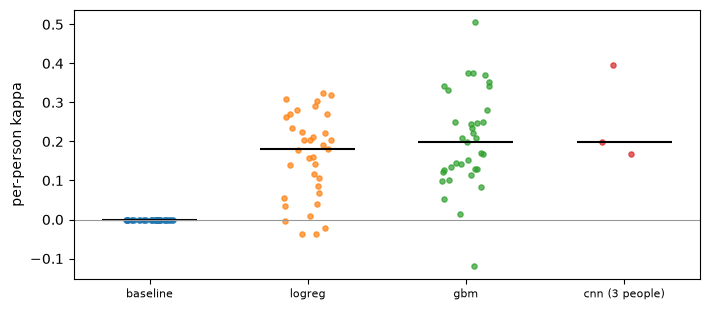

In [ ]:
from metrics import kappa_per_person, bootstrap_ci


def kappa_table(preds, name):
    k = kappa_per_person(preds, LABELS)
    med, lo, hi = bootstrap_ci(k)
    print(f"{name}: median per-person kappa {med:.3f}  95% CI [{lo:.3f}, {hi:.3f}]"
          f"  people with a value {k.notna().sum()}/{len(k)}")
    return k


def kappa_dots(kappas):
    fig, ax = plt.subplots(figsize=(1.6 + 1.4 * len(kappas), 3.2))
    for i, (name, k) in enumerate(kappas.items()):
        v = k.dropna().to_numpy()
        jit = np.random.default_rng(0).uniform(-0.15, 0.15, v.size)
        ax.scatter(np.full(v.size, i) + jit, v, s=14, alpha=0.7)
        ax.hlines(np.median(v), i - 0.3, i + 0.3, color="k")
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_xticks(range(len(kappas))); ax.set_xticklabels(list(kappas), fontsize=8)
    ax.set_ylabel("per-person kappa")
    plt.tight_layout(); plt.show()


all_preds = {"baseline": preds_base, "logreg": preds_lr, "gbm": preds_gbm}
if "preds_cnn" in globals():
    all_preds["cnn (3 people)"] = preds_cnn
kappas = {nm: kappa_table(p, nm) for nm, p in all_preds.items()}
kappa_dots(kappas)

['W' 'NREM' 'REM']
REM vs NREM: strongest column temp_mean_z_past4, median AUC 0.604, 17/28 people above 0.5
W vs NREM: strongest column motion_z_next4, median AUC 0.731, 34/34 people above 0.5


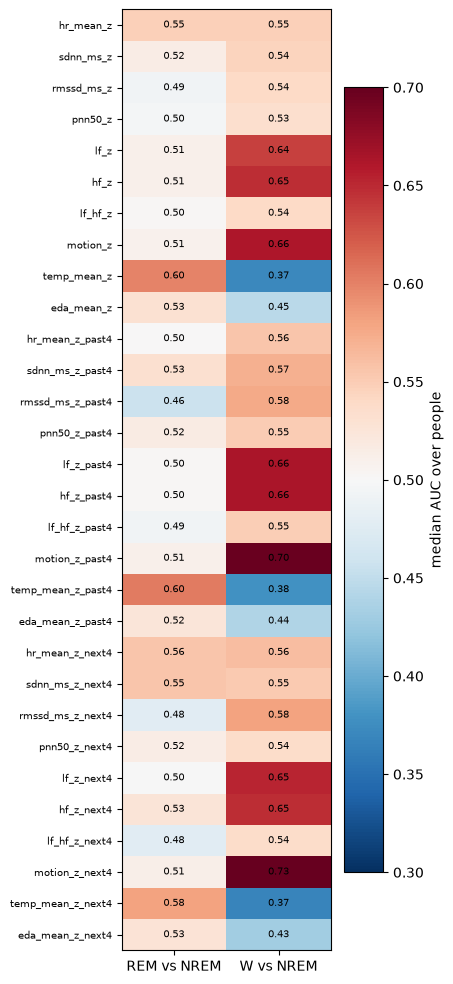

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import rankdata

Z = [c for c in df.columns if c.endswith("_z")]
cols = Z + [c + "_past4" for c in Z] + [c + "_next4" for c in Z]
print(df["stage3"].unique())          # check the label spelling first

def auc(a, b):
    """P(random a > random b), ties count half."""
    r = rankdata(np.concatenate([a, b]))
    return (r[:len(a)].sum() - len(a) * (len(a) + 1) / 2) / (len(a) * len(b))

pairs = {"REM vs NREM": ("REM", "NREM"), "W vs NREM": ("W", "NREM")}
rows = []
for p, g in df.groupby("subject"):
    for name, (s1, s2) in pairs.items():
        for c in cols:
            a = g.loc[g.stage3 == s1, c].dropna().values
            b = g.loc[g.stage3 == s2, c].dropna().values
            if len(a) >= 30 and len(b) >= 30:
                rows.append((p, name, c, auc(a, b)))
res = pd.DataFrame(rows, columns=["subject", "pair", "col", "auc"])

summ = (res.groupby(["col", "pair"])["auc"]
           .agg(median="median", n_people="size", n_above=lambda x: (x > 0.5).sum())
           .reset_index())
grid = summ.pivot(index="col", columns="pair", values="median").reindex(cols)

# the number
for pair in pairs:
    m = grid[pair]
    best = (m - 0.5).abs().idxmax()
    row = summ[(summ.col == best) & (summ.pair == pair)].iloc[0]
    print(f"{pair}: strongest column {best}, median AUC {m[best]:.3f}, "
          f"{row.n_above}/{row.n_people} people above 0.5")

# the figure
fig, ax = plt.subplots(figsize=(4.5, 10))
im = ax.imshow(grid.values, cmap="RdBu_r", vmin=0.3, vmax=0.7, aspect="auto")
ax.set_xticks(range(grid.shape[1])); ax.set_xticklabels(grid.columns)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=7)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, label="median AUC over people")
plt.tight_layout(); plt.show()

cnn fold 35/35 done, 572s elapsed
cnn: median per-person macro F1 0.363  95% CI [0.327, 0.404]  people 35  mean stages averaged 2.97
same people, other models:
  baseline: median 0.278
  logreg: median 0.403
  gbm: median 0.409


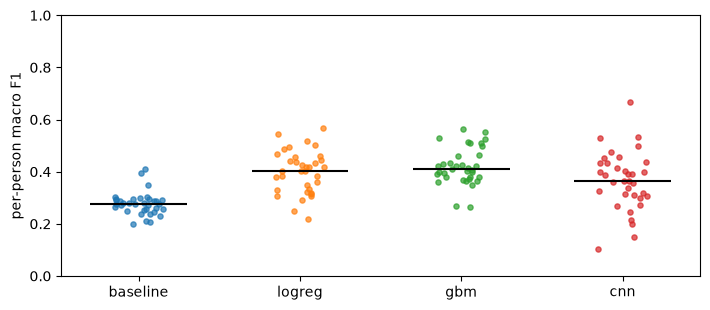

In [ ]:
CNN_FOLDS = folds
preds_cnn = run_folds(lambda: CNNModel(causal=False), Xseq, y, subjects, index, CNN_FOLDS, "cnn")
tab_cnn = score(preds_cnn, "cnn")
common = tab_cnn.index
print("same people, other models:")
for nm, t in [("baseline", tab_base), ("logreg", tab_lr), ("gbm", tab_gbm)]:
    print(f"  {nm}: median {t.loc[common, 'macro_f1'].median():.3f}")
dot_plot({"baseline": tab_base.loc[common], "logreg": tab_lr.loc[common],
          "gbm": tab_gbm.loc[common], "cnn": tab_cnn})

In [ ]:
preds_cnn.to_csv("../data/derived/preds_cnn.csv", index=False)

In [ ]:
from sklearn.metrics import cohen_kappa_score


# LOGIC: per draw, each fold gets one random order of its training people; size n uses the
#   first n of that order, so smaller sets sit inside larger ones. Same test people and
#   same C at every size. Kappa is pooled over all test epochs, as in the earlier runs.
# EDGE CASES: a small set can lack a stage. run_folds would raise, so this loop does not;
#   the number of such folds is recorded in folds_missing_stage.
# NOT HANDLED: retuning per size (logreg ignores the tune people).
# CHECKED BY: size 30 must equal tab_lr, asserted in the next cell.
def learning_curve(model_factory, X, y, subjects, folds, sizes, n_draws, seed):
    rng = np.random.default_rng(seed)
    rows = []
    for d in range(n_draws):
        order = [rng.permutation(f["train"]) for f in folds]
        for n in sizes:
            parts, miss = [], 0
            for f, o in zip(folds, order):
                tr = np.isin(subjects, o[:n]); te = np.isin(subjects, f["test"])
                miss += len(np.unique(y[tr])) < len(CLASSES)
                yhat = np.asarray(model_factory().fit(X[tr], y[tr]).predict(X[te])).astype(int)
                parts.append(pd.DataFrame({"subject": subjects[te], "y": y[te], "yhat": yhat}))
            p = pd.concat(parts, ignore_index=True)
            t = macro_f1_per_person(p, LABELS)
            rows.append({"draw": d, "size": n, "median_f1": t["macro_f1"].median(),
                         "kappa": cohen_kappa_score(p.y, p.yhat), "folds_missing_stage": miss})
            print(f"draw {d + 1}/{n_draws} size {n} done", end="\r")
    print()
    return pd.DataFrame(rows)

#Cell 2, run, number and figure:

SIZES = list(range(2, 31, 2))   # 15 sizes; 2 is the floor (1 person can give one stage, logreg raises), 30 = full train set
N_DRAWS = 10
curve = learning_curve(lambda: LogRegFeatures(C=best_C), X, y, subjects, folds, SIZES, N_DRAWS, SEED)
assert np.allclose(curve.loc[curve["size"] == 30, "median_f1"], tab_lr["macro_f1"].median())

summary = curve.groupby("size").agg(f1_mean=("median_f1", "mean"), f1_min=("median_f1", "min"),
                                    f1_max=("median_f1", "max"), kappa_mean=("kappa", "mean"),
                                    folds_missing=("folds_missing_stage", "mean"))
print(summary.round(3).to_string())

fig, ax = plt.subplots(figsize=(4.5, 3.2))
for d, g in curve.groupby("draw"):
    ax.plot(g["size"], g["median_f1"], color="grey", lw=0.8, alpha=0.6)
ax.plot(summary.index, summary["f1_mean"], color="k", lw=2)
ax.axhline(tab_base["macro_f1"].median(), ls=":", color="k")
ax.set_xlabel("training people"); ax.set_ylabel("median per-person macro F1")
plt.tight_layout(); plt.show()

NameError: name 'SIZES' is not defined

## 12. Feature groups: does a group improve logreg?

One loop for every group.

`build_group` logic: for each person, load the `Recording`, take the same kept epochs as `features_all35.csv`, and call the group's `compute(rec, ss, ts)`. It returns one row of raw columns per epoch. Rows are lined up with `df` by (subject, epoch); any mismatch raises. For a heart group (`gated=True`) the columns are NaN where `df["pass"]` is False (option a). Then the same treatment as notebook 05: per-person z score over the night, then `_past4` and `_next4` of each z column. Saved as `data/derived/features_plus_<name>.csv`. If that file exists it is loaded, not rebuilt. `features_all35.csv` is never written.

`evaluate_group` logic: logreg on the current 30 columns plus the group's z, past4 and next4 columns. Same folds, same `TUNE_FOLDS`, same C grid as model 1a, so the only change is the inputs. Predictions go to `data/derived/preds_logreg_plus_<name>.csv`. It prints, for the current logreg and for logreg plus the group: median per-person macro F1, pooled kappa, REM recall (share of true REM epochs predicted REM), and the false-REM rate (share of true NREM epochs predicted REM). Then the paired difference: per person, macro F1 with the group minus without, median and 95% interval over people. Figure: dot plot of baseline, logreg, logreg plus the group.

The tuning carries the same mild leak as model 1a (open item 17), on both sides of the comparison.

In [36]:
import gc, importlib, tempfile
import features; importlib.reload(features)          # pick up functions added to src/features.py
from features import normalise_per_person, context_features, pulse_amplitude
from sklearn.metrics import cohen_kappa_score
from metrics import paired_difference
from recording import Recording
DERIVED = ROOT / "data" / "derived"


# LOGIC: see the markdown above.
# EDGE CASES: compute returning the wrong number of rows raises; keys not matching base
#   raise; a new column name already in base raises; an existing file is loaded.
# NOT HANDLED: causal scaling and causal context (offline only, like the current CSV).
# CHECKED BY: the next cell (fake recordings).
def build_group(name, compute, gated, people, load, base, out_dir=DERIVED):
    """compute(rec, ss, ts) -> DataFrame, one row per kept epoch (raw columns only).
    load(person) -> Recording. base: the epoch table (subject, epoch, pass).
    Returns a DataFrame on base's index: raw, _z, _z_past4, _z_next4 columns."""
    path = Path(out_dir) / f"features_plus_{name}.csv"
    if path.exists():
        G = pd.read_csv(path)
    else:
        parts = []
        for s in people:
            rec = load(s)
            ep = rec.epochs; k = ep.keep.to_numpy(bool)
            ss = ep.start_sample_wrist.to_numpy()[k]
            f = compute(rec, ss, rec.t64[ss]).reset_index(drop=True)
            if len(f) != k.sum():
                raise ValueError(f"{s}: compute gave {len(f)} rows for {k.sum()} epochs")
            f.insert(0, "epoch", np.flatnonzero(k)); f.insert(0, "subject", s)
            parts.append(f)
            del rec; gc.collect()
            print(s, end=" ", flush=True)
        print()
        G = pd.concat(parts, ignore_index=True)
    raw = [c for c in G.columns if c not in ("subject", "epoch") and not c.endswith(("_z", "_past4", "_next4"))]
    clash = [c for c in raw if c in base.columns]
    if clash:
        raise ValueError(f"columns already in the epoch table: {clash}")
    key = base[["subject", "epoch", "pass"]]
    M = key.reset_index().merge(G, on=["subject", "epoch"], how="left", validate="one_to_one", indicator=True)
    if len(G) != len(key) or (M["_merge"] != "both").any():
        raise ValueError(f"{name}: rows do not match the epoch table one to one")
    M = M.set_index("index").drop(columns="_merge"); M.index.name = None
    if not path.exists():
        if gated:
            M.loc[~M["pass"].to_numpy(bool), raw] = np.nan
        Zg = normalise_per_person(M, raw); Zg.columns = [c + "_z" for c in raw]
        M = pd.concat([M, Zg], axis=1)
        M = pd.concat([M, context_features(M, list(Zg.columns), k=4)], axis=1)
        M.drop(columns="pass").to_csv(path, index=False)
    return M.drop(columns=["subject", "epoch", "pass"])

In [37]:
class _FakeRec:
    def __init__(self, n, drop):
        keep = np.ones(n, bool); keep[drop] = False
        self.epochs = pd.DataFrame({"keep": keep, "start_sample_wrist": np.arange(n) * 1920})
        self.t64 = np.arange(n * 1920 + 1) / 64.0

base_t = pd.DataFrame({"subject": ["A"] * 3 + ["B"] * 4, "epoch": [0, 2, 3, 0, 1, 2, 3],
                       "pass": [True, False, True, True, True, True, False]})
fake = {"A": _FakeRec(4, [1]), "B": _FakeRec(4, [])}
comp = lambda rec, ss, ts: pd.DataFrame({"feat": ts.astype(float)})
with tempfile.TemporaryDirectory() as tmp:
    G = build_group("t", comp, True, ["B", "A"], fake.get, base_t, tmp)     # build order differs from base
    assert list(G.index) == list(base_t.index)
    assert np.allclose(G["feat"], [0, np.nan, 90, 0, 30, 60, np.nan], equal_nan=True)
    assert np.isnan(G.loc[[1, 6], "feat_z"]).all()                          # gated epochs are NaN
    assert np.isclose(G.loc[0, "feat_z"], (0 - 45) / np.std([0, 90], ddof=1))   # z within person A
    assert {"feat_z_past4", "feat_z_next4"} <= set(G.columns)
    assert np.isnan(G.loc[0, "feat_z_past4"]) and np.isclose(G.loc[2, "feat_z_past4"], G.loc[0, "feat_z"])
    G2 = build_group("t", comp, True, ["B", "A"], fake.get, base_t, tmp)    # second call loads the file
    assert np.allclose(G.to_numpy(float), G2.to_numpy(float), equal_nan=True)
    try:
        build_group("u", comp, True, ["A"], fake.get, base_t, tmp); raise SystemExit("missing person not caught")
    except ValueError:
        pass
    try:
        build_group("v", lambda r, s, t: pd.DataFrame({"pass": t}), False, ["B", "A"], fake.get, base_t, tmp)
        raise SystemExit("name clash not caught")
    except ValueError:
        pass
print("build_group: all checks passed")

B A 
A 
B A 
build_group: all checks passed


In [38]:
# LOGIC: REM recall = share of true REM epochs predicted REM; false-REM rate = share of
#   true NREM epochs predicted REM. Both pooled over all test epochs.
# EDGE CASES: no REM (or no NREM) epochs gives NaN.
# CHECKED BY: the test cell below.
def rem_rates(preds, rem=2, nrem=1):
    y, yh = preds["y"].to_numpy(), preds["yhat"].to_numpy()
    r, n = y == rem, y == nrem
    return (float((yh[r] == rem).mean()) if r.any() else np.nan,
            float((yh[n] == rem).mean()) if n.any() else np.nan)


def _summary_row(name, preds, tab):
    rr, fr = rem_rates(preds)
    return {"model": name, "median_macro_f1": tab["macro_f1"].median(),
            "kappa_pooled": cohen_kappa_score(preds["y"], preds["yhat"]),
            "rem_recall": rr, "false_rem_on_nrem": fr}


# LOGIC: see the markdown above.
# EDGE CASES: same rows and people as model 1a because make_xy drops the same NaN labels.
# NOT HANDLED: per-fold tuning (open item 17); class probabilities.
# CHECKED BY: its parts are tested (make_xy, run_folds, tune_settings, rem_rates); the
#   current-logreg row must reproduce 0.403.
def evaluate_group(name, G, ref_preds, ref_tab):
    new = [c for c in G.columns if c.endswith(("_z", "_z_past4", "_z_next4"))]
    Xg, yg, sg, ig = make_xy(df.join(G[new]), COLS + new)
    tune = tune_settings(lambda **s: LogRegFeatures(**s), lr_settings, Xg, yg, sg, TUNE_FOLDS)
    C = lr_settings[int(tune.iloc[0]["setting"])]["C"]
    preds = run_folds(lambda: LogRegFeatures(C=C), Xg, yg, sg, ig, folds, f"logreg+{name}")
    preds.to_csv(DERIVED / f"preds_logreg_plus_{name}.csv", index=False)
    tab = macro_f1_per_person(preds, LABELS)
    print(f"{len(new)} new columns, chosen C {C:.4g}")
    print(pd.DataFrame([_summary_row("logreg", ref_preds, ref_tab),
                        _summary_row(f"logreg+{name}", preds, tab)]).set_index("model").round(3).to_string())
    d = paired_difference(tab["macro_f1"], ref_tab["macro_f1"])
    print(f"per-person macro F1, with minus without: median {d['median']:+.3f}  "
          f"95% CI [{d['lo']:+.3f}, {d['hi']:+.3f}]  people {d['n']}")
    dot_plot({"baseline": tab_base, "logreg": ref_tab, f"+{name}": tab})
    return preds, tab

In [39]:
p = pd.DataFrame({"y": [2, 2, 2, 2, 1, 1, 1, 1, 1, 0], "yhat": [2, 2, 1, 0, 2, 1, 1, 1, 1, 0]})
assert rem_rates(p) == (0.5, 0.2)                                        # 2 of 4 REM found; 1 of 5 NREM called REM
assert np.isnan(rem_rates(p[p.y != 2])[0])
for nm, pr in [("baseline", preds_base), ("logreg", preds_lr)]:          # save once so nothing is rerun
    f = DERIVED / f"preds_{nm}.csv"
    if not f.exists():
        pr.to_csv(f, index=False)
print("rem_rates: all checks passed")

rem_rates: all checks passed


### Group 1: pulse amplitude. HEAVY (first run detects beats for all 35, as notebook 05 did)

`pulse_amplitude` in `src/features.py`: per beat, peak minus the lowest point since the previous peak, kept beats only; per epoch the mean, std and CV, NaN under 3 beats. Gated: NaN where the heart features are NaN.

S006 S009 S010 S012 S013 S014 S015 S021 S022 S024 S030 S032 S035 S042 S045 S047 S055 S058 S061 S064 S070 S072 S074 S075 S080 S085 S086 S093 S094 S096 S097 S100 S101 S102 S103 
share of epochs with amp_mean missing: 0.257
setting 8/8: tune macro F1 0.403
logreg+amp fold 35/35 done, 12s elapsed
9 new columns, chosen C 100
            median_macro_f1  kappa_pooled  rem_recall  false_rem_on_nrem
model                                                                   
logreg                0.403         0.172       0.457              0.358
logreg+amp            0.399         0.167       0.403              0.351
per-person macro F1, with minus without: median +0.002  95% CI [-0.006, +0.011]  people 35


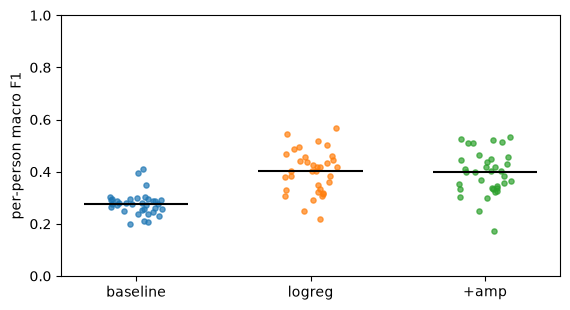

In [40]:
G_amp = build_group("amp",
                    lambda rec, ss, ts: pulse_amplitude(rec.bvp_filt, rec.beat_idx, rec.intervals, ss, 64, 30),
                    gated=True, people=people, load=lambda s: Recording.load(s, DATA_ROOT), base=df)
print("share of epochs with amp_mean missing:", round(float(G_amp["amp_mean"].isna().mean()), 3))
preds_amp, tab_amp = evaluate_group("amp", G_amp, preds_lr, tab_lr)